# Exploratory data analysis: historical financial figures and prices

This notebook inspects the source workbook, investigates the MGS price anomaly, and applies the project's existing cleaning functions. The raw DataFrames remain available for comparison. Run the cells in order from the project root or the `notebooks` directory.


## 1. Setup and Data Loading

Load both worksheets from the project workbook. Daily dates are parsed as in the original notebook; annual availability dates remain in their source form until the cleaning step. No files are written.


In [278]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display

project_root = Path.cwd().resolve()
if project_root.name == "notebooks":
    project_root = project_root.parent

workbook = project_root / "data" / "Raw" / "Historical_Data.xlsx"
if not workbook.is_file():
    raise FileNotFoundError(f"Source workbook not found: {workbook}")

if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

from src.data_cleaner import clean_annual_figures, clean_daily_prices
from src.validation import validate_annual_figures, validate_daily_prices
from src.outlier_checks import (
    annual_outliers, annual_ratio_flags, known_annual_errors,
    neighboring_year_outliers, price_discontinuities,
    robust_return_outliers,
)

annual_figures = pd.read_excel(workbook, sheet_name="Annual figures")
prices = pd.read_excel(workbook, sheet_name="Daily prices", parse_dates=["Date"])


## ⭐ 2. Dataset Overview

`annual_figures` contains company and year financial observations, including fundamentals and sector specific fields. `prices` contains daily closing prices for the company tickers and a benchmark. These raw DataFrames are retained throughout the notebook.


In [279]:
print(f"Annual figures: {annual_figures.shape[0]:,} rows × {annual_figures.shape[1]} columns")
print(f"Daily prices: {prices.shape[0]:,} rows × {prices.shape[1]} columns")
display(annual_figures.head(), prices.head())


Annual figures: 200 rows × 20 columns
Daily prices: 2,529 rows × 22 columns


,ticker,company,sector,year,sales_gbp_m,profit_gbp_m,operating_cash_flow_gbp_m,capital_spending_gbp_m,free_cash_flow_gbp_m,debt_gbp_m,cash_gbp_m,shares_m,dividend_per_share_gbp,employees,followers_thousands,loans_overdue,capital_cushion,claims_ratio,capital_coverage,available_date
0,NCL,Northstar Cloud,Technology,2016,841.46,63.11,68.16,34.50,33.66,518.34,109.39,314.2972,0.044175,2356,1922,NaN,NaN,NaN,NaN,2017-03-31
1,NCL,Northstar Cloud,Technology,2017,957.67,79.97,94.55,43.97,50.59,554.17,131.95,314.9258,0.055862,2681,4276,NaN,NaN,NaN,NaN,2018-03-31
2,NCL,Northstar Cloud,Technology,2018,1085.96,90.77,117.45,45.89,71.56,587.86,158.07,315.5556,0.063284,3041,1939,NaN,NaN,NaN,NaN,2019-03-31
3,NCL,Northstar Cloud,Technology,2019,1215.02,129.86,133.94,52.82,81.11,612.37,186.30,316.1867,0.090357,3402,4088,NaN,NaN,NaN,NaN,2020-03-31
4,NCL,Northstar Cloud,Technology,2020,1384.12,149.10,159.37,59.05,100.32,645.92,223.00,316.8191,0.103534,3876,2677,NaN,NaN,NaN,NaN,2021-03-31


,Date,NCL,BFC,MGS,FAI,GVH,HLM,ORP,VGB,HHM,...,THL,APR,VTF,CSE,HBL,CDB,LNP,CRM,BSL,BENCHMARK
0,2016-01-04,13.318054,3.394548,3.189580,462.255723,24.138157,8.661885,1.315784,12.383055,15.860037,...,0.944907,7.056835,5.853684,2.724644,2.861988,0.733089,4.598693,1.590654,0.459142,100.000000
1,2016-01-05,13.572615,3.459573,3.196597,466.620997,23.968171,8.656789,1.346751,12.090068,15.906895,...,0.933262,7.222704,6.079697,2.771176,2.840797,0.743347,4.604306,1.612147,0.464144,100.455380
2,2016-01-06,13.647415,3.472841,3.185503,469.665162,24.074871,8.563410,1.349824,12.286334,15.839410,...,0.949839,7.313535,5.979872,2.709436,2.824841,0.734243,4.565032,1.621895,0.460382,99.609793
3,2016-01-07,13.403608,3.442699,3.172154,466.404778,24.071718,8.620814,1.355481,12.131758,15.548912,...,0.935078,7.427067,5.716630,2.681633,2.881170,0.724731,4.550035,1.611331,0.462180,99.340280
4,2016-01-08,13.567313,3.367108,3.198890,461.282710,24.424538,8.669508,1.366976,12.193678,15.582383,...,0.945793,7.576666,5.897947,2.727294,2.910163,0.739044,4.702576,1.638070,0.464438,99.286421


In [280]:
print("Annual figures columns and types:")
display(annual_figures.dtypes.rename("dtype").to_frame())
print("Daily prices columns and types:")
display(prices.dtypes.rename("dtype").to_frame())


Annual figures columns and types:


,dtype
ticker,str
company,str
sector,str
year,int64
sales_gbp_m,float64
profit_gbp_m,float64
operating_cash_flow_gbp_m,float64
capital_spending_gbp_m,float64
free_cash_flow_gbp_m,float64
debt_gbp_m,float64


Daily prices columns and types:


,dtype
Date,datetime64[us]
NCL,float64
BFC,float64
MGS,float64
FAI,float64
GVH,float64
HLM,float64
ORP,float64
VGB,float64
HHM,float64


### One company across all years

Change `selected_ticker` to another code to inspect all of that company's annual source figures, ordered by fiscal year. The following chart uses the same company; change `selected_metric` to choose which numeric annual figure to plot. This view uses the raw data, so confirmed source errors remain visible; Section 10 applies the documented corrections.


In [306]:
selected_ticker = "APR"  # Change this to the company ticker you want.
company_years = annual_figures.loc[annual_figures["ticker"].eq(selected_ticker)].sort_values("year")
if company_years.empty:
    available = ", ".join(sorted(annual_figures["ticker"].dropna().unique()))
    raise ValueError(f"Unknown ticker {selected_ticker!r}. Choose from: {available}")
with pd.option_context("display.max_columns", None):
    display(company_years.reset_index(drop=True))


,ticker,company,sector,year,sales_gbp_m,profit_gbp_m,operating_cash_flow_gbp_m,capital_spending_gbp_m,free_cash_flow_gbp_m,debt_gbp_m,cash_gbp_m,shares_m,dividend_per_share_gbp,employees,followers_thousands,loans_overdue,capital_cushion,claims_ratio,capital_coverage,available_date
0,APR,Apex Rail,Industrials,2016,995.21,64.69,79.76,44.93,34.83,375.34,68.65,220.9902,0.064399,3185,1866,NaN,NaN,NaN,NaN,2017-03-31
1,APR,Apex Rail,Industrials,2017,1091.48,74.24,101.69,51.35,50.33,386.69,79.79,221.4322,0.073758,3493,491,NaN,NaN,NaN,NaN,2018-03-31
2,APR,Apex Rail,Industrials,2018,1250.48,92.84,118.19,55.94,62.26,414.45,96.58,221.8750,0.092051,4002,1526,NaN,NaN,NaN,NaN,2019-03-31
3,APR,Apex Rail,Industrials,2019,1382.99,119.81,139.61,69.53,70.08,426.75,112.52,222.3188,0.118561,4426,2113,NaN,NaN,NaN,NaN,2020-03-31
4,APR,Apex Rail,Industrials,2020,1328.76,117.76,137.65,65.34,72.32,379.65,113.59,222.7634,0.116294,4252,4100,NaN,NaN,NaN,NaN,2021-03-31
5,APR,Apex Rail,Industrials,2021,1564.74,151.24,181.69,76.25,105.44,411.30,140.22,223.2090,0.149063,5007,4016,NaN,NaN,NaN,NaN,2022-03-31
6,APR,Apex Rail,Industrials,2022,1724.12,172.42,216.00,84.09,131.92,413.79,161.62,223.6554,0.169597,5517,4858,NaN,NaN,NaN,NaN,2023-03-31
7,APR,Apex Rail,Industrials,2023,1991.71,222.60,248.75,95.13,153.62,432.49,194.93,224.1027,0.218527,6373,3051,NaN,NaN,NaN,NaN,2024-03-31
8,APR,Apex Rail,Industrials,2024,2222.92,274.05,268.14,98.50,169.64,431.88,226.73,224.5509,0.268496,7113,2178,NaN,NaN,NaN,NaN,2025-03-31
9,APR,Apex Rail,Industrials,2025,2450.00,318.50,342.37,109.62,232.75,420.00,260.00,225.0000,0.311422,7840,1531,NaN,NaN,NaN,NaN,2025-12-31


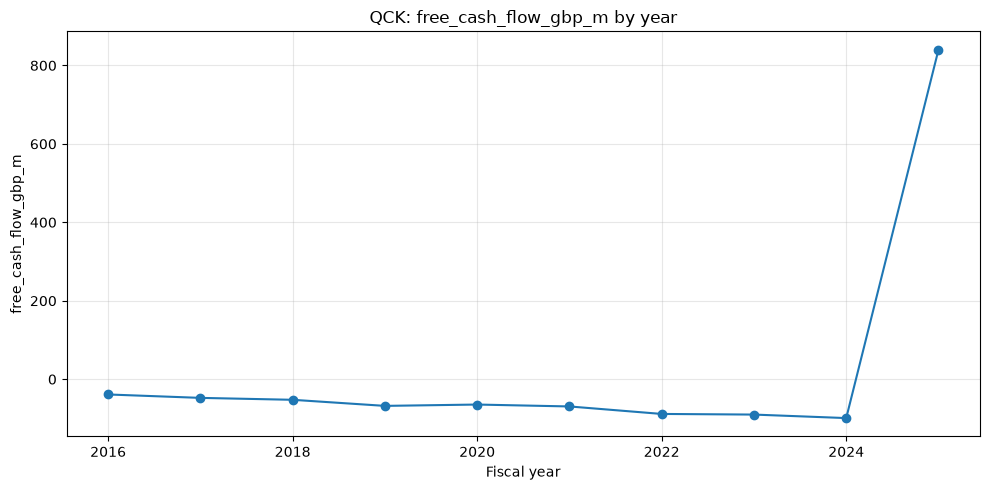

In [302]:
selected_metric = "free_cash_flow_gbp_m"  # Change this to another numeric annual column.
available_metrics = [column for column in company_years.select_dtypes(include="number") if column != "year"]
if selected_metric not in available_metrics:
    raise ValueError(f"Choose a numeric annual metric from: {available_metrics}")
fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(company_years["year"], company_years[selected_metric], marker="o")
ax.set(title=f"{selected_ticker}: {selected_metric} by year", xlabel="Fiscal year", ylabel=selected_metric)
ax.grid(alpha=0.3)
fig.tight_layout()
plt.show()


## ⭐ 3. Data Quality Assessment

Inspect missingness, record and identifier duplicates, date coverage, and price validity before cleaning. Sector specific annual fields may be absent by design; missing values are reported rather than filled.


In [283]:
print("Missing values in annual figures:")
display(annual_figures.isna().sum().rename("missing_count").to_frame())
print("Missing values in daily prices:")
display(prices.isna().sum().rename("missing_count").to_frame())

print("Duplicate annual rows:", annual_figures.duplicated().sum())
print("Duplicate company-year identifiers:", annual_figures.duplicated(["ticker", "year"]).sum())
print("Duplicate daily rows:", prices.duplicated().sum())
print("Duplicate trading dates:", prices["Date"].duplicated().sum())


Missing values in annual figures:


,missing_count
ticker,0
company,0
sector,0
year,0
sales_gbp_m,0
profit_gbp_m,0
operating_cash_flow_gbp_m,30
capital_spending_gbp_m,30
free_cash_flow_gbp_m,30
debt_gbp_m,30


Missing values in daily prices:


,missing_count
Date,0
NCL,0
BFC,0
MGS,0
FAI,0
GVH,0
HLM,0
ORP,0
VGB,0
HHM,0


Duplicate annual rows: 0
Duplicate company-year identifiers: 0
Duplicate daily rows: 0
Duplicate trading dates: 0


In [284]:
annual_dates = pd.to_datetime(annual_figures["available_date"], errors="coerce")
price_dates = pd.to_datetime(prices["Date"], errors="coerce")

print("Annual fiscal years:", annual_figures["year"].min(), "to", annual_figures["year"].max())
print("Annual availability dates:", annual_dates.min(), "to", annual_dates.max())
print("Trading dates:", price_dates.min(), "to", price_dates.max())
print("Invalid annual availability dates:", annual_dates.isna().sum())
print("Invalid trading dates:", price_dates.isna().sum())


Annual fiscal years: 2016 to 2025
Annual availability dates: 2017-03-31 00:00:00 to 2025-12-31 00:00:00
Trading dates: 2016-01-04 00:00:00 to 2025-12-31 00:00:00
Invalid annual availability dates: 0
Invalid trading dates: 0


### ⭐ <u>Free cash flow consistency: QCK 2025</u>

The project defines free cash flow (FCF) as operating cash flow minus capital spending. Check the source values before cleaning, allowing the 0.02 million rounding tolerance used by `validate_annual_figures`. Rows without all three inputs are not comparable and remain missing; this check does not impute them.

**QCK 2025 — FCF discrepancy:** The source reports **£840.0m**, but operating cash flow of £149.51m less capital spending of £233.51m equals **−£84.0m**. The table below isolates this mismatch.


In [285]:
raw_annual_checks = validate_annual_figures(annual_figures)
print("Raw annual validation:")
display(pd.Series(raw_annual_checks, name="result").to_frame())

raw_expected_fcf = (
    annual_figures["operating_cash_flow_gbp_m"]
    - annual_figures["capital_spending_gbp_m"]
)
raw_fcf_difference = raw_expected_fcf - annual_figures["free_cash_flow_gbp_m"]
fcf_mismatch = raw_fcf_difference.abs() > 0.02

print("Source FCF mismatches:")
display(
    annual_figures.loc[
        fcf_mismatch,
        ["ticker", "year", "operating_cash_flow_gbp_m",
         "capital_spending_gbp_m", "free_cash_flow_gbp_m"],
    ].assign(expected_fcf_gbp_m=raw_expected_fcf.loc[fcf_mismatch])
)
print("Rows without all three FCF inputs:", raw_fcf_difference.isna().sum())


Raw annual validation:


,result
duplicate_company_years,0
invalid_dates,0
missing_tickers,0
invalid_shares,0
fcf_mismatches,1


Source FCF mismatches:


,ticker,year,operating_cash_flow_gbp_m,capital_spending_gbp_m,free_cash_flow_gbp_m,expected_fcf_gbp_m
99,QCK,2025,149.51,233.51,840.0,-84.0


Rows without all three FCF inputs: 30


### ⭐ Visual screening across companies

Plot a common annual measure, sales in GBP millions, for every company. Sector specific fields are not suitable for this overview because they are missing for most companies. Then plot every company's raw daily closing prices, excluding the benchmark. These charts show the broad pattern before investigating any single observation; price levels differ across companies, so the daily chart is a screen for unusual shapes rather than a comparison of performance.


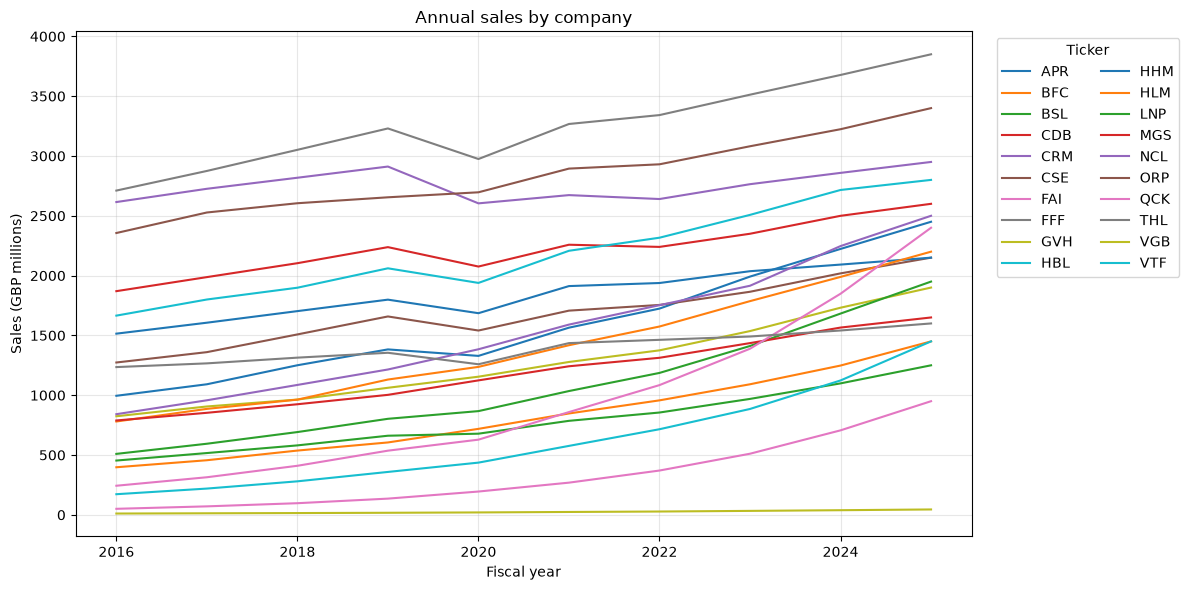

In [286]:
fig, ax = plt.subplots(figsize=(12, 6))
for ticker, company_data in annual_figures.groupby("ticker", sort=True):
    company_data = company_data.sort_values("year")
    ax.plot(company_data["year"], company_data["sales_gbp_m"], label=ticker)

ax.set(
    title="Annual sales by company",
    xlabel="Fiscal year",
    ylabel="Sales (GBP millions)",
)
ax.grid(alpha=0.3)
ax.legend(
    title="Ticker", bbox_to_anchor=(1.02, 1), loc="upper left", ncol=2
)
fig.tight_layout()
plt.show()


In [287]:
# Uncomment this block and change the sector name to plot one sector only.
# selected_sector = "Technology"
# sector_data = annual_figures.loc[annual_figures["sector"].eq(selected_sector)]
# fig, ax = plt.subplots(figsize=(12, 6))
# for ticker, company_data in sector_data.groupby("ticker", sort=True):
#     company_data = company_data.sort_values("year")
#     ax.plot(company_data["year"], company_data["sales_gbp_m"], label=ticker)
# ax.set(title=f"Annual sales: {selected_sector}", xlabel="Fiscal year", ylabel="Sales (GBP millions)")
# ax.grid(alpha=0.3)
# ax.legend(title="Ticker", bbox_to_anchor=(1.02, 1), loc="upper left")
# fig.tight_layout()
# plt.show()

# To see the available sector names, run:
display(sorted(annual_figures["sector"].dropna().unique()))


['Consumer', 'Financials', 'Healthcare', 'Industrials', 'Technology']

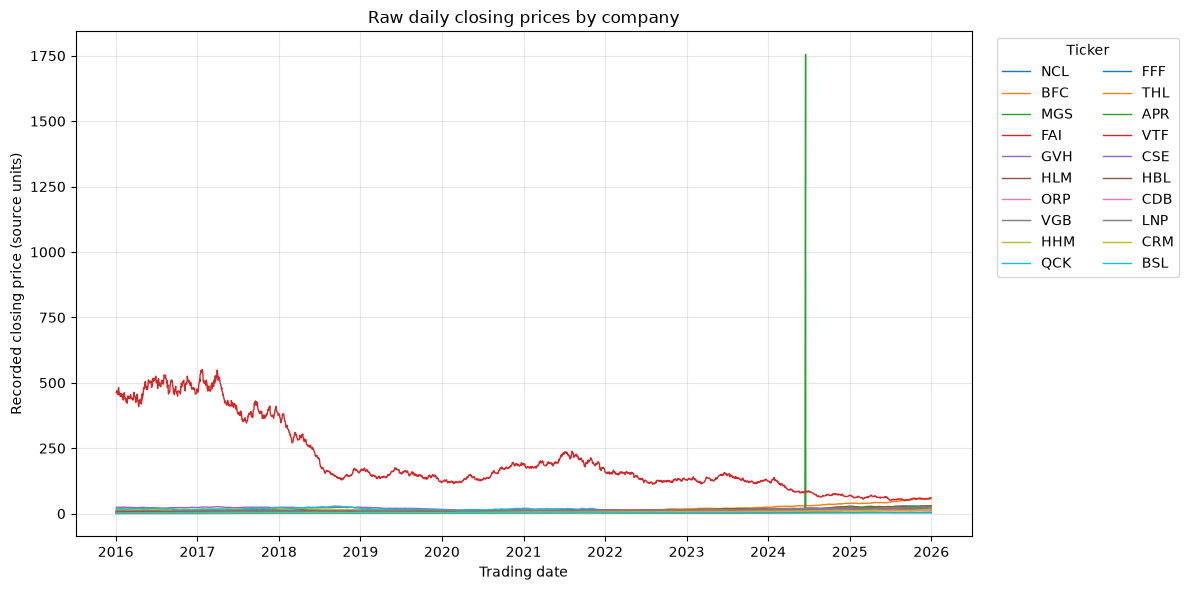

In [288]:
company_tickers = [
    ticker for ticker in prices.columns if ticker not in ("Date", "BENCHMARK")
]
prices_by_date = prices.sort_values("Date")

fig, ax = plt.subplots(figsize=(12, 6))
for ticker in company_tickers:
    ax.plot(
        prices_by_date["Date"], prices_by_date[ticker], label=ticker, linewidth=1
    )

ax.set(
    title="Raw daily closing prices by company",
    xlabel="Trading date",
    ylabel="Recorded closing price (source units)",
)
ax.grid(alpha=0.3)
ax.legend(
    title="Ticker", bbox_to_anchor=(1.02, 1), loc="upper left", ncol=2
)
fig.tight_layout()
plt.show()


**MGS 17 June 2024 — price spike spotted:** The daily overview shows an isolated close near **1,755.51**, while adjacent closes are near **17**. The ranked return check and focused June investigation below examine this observation. The chart alone does not establish the cause.


The next checks identify non positive prices and extreme one day price changes. Negative financial flows or profits are not automatically invalid, so this notebook does not modify them.


## ⭐ 4. Robust Daily Return Outliers

The largest-return ranking above is useful for discovery, but it can be dominated by one known anomaly and does not account for how volatile each ticker usually is. This screen computes daily percentage returns for each company and compares them with that ticker’s own median return using the median absolute deviation (MAD). A robust score with absolute value at least 6 is flagged. This is a screening threshold, not a statistical verdict: genuine news-driven moves can be extreme, and thin or unusually stable series can make scores less informative. Each result should be checked against neighboring prices and source records. The benchmark is omitted because company-specific behavior is the focus.

In [289]:
daily_return_flags = robust_return_outliers(prices)
print(f"Robust daily return flags: {len(daily_return_flags)}")
display(daily_return_flags.sort_values("score", key=lambda s: s.abs(), ascending=False).head(30))

Robust daily return flags: 2


,ticker,date,metric,value,score,reason
0,MGS,2024-06-17,daily_return,99.985263,10628.034802,absolute robust score >= 6
1,MGS,2024-06-18,daily_return,-0.990096,-105.351710,absolute robust score >= 6


## ⭐ <u>5. Annual Financial Outliers and Changes: BSL 2025</u>

Annual values are compared within each ticker, not across companies, because firms differ greatly in size and sector. The existing MAD screen flags unusual levels and yearly changes in common financial measures. A second screen checks every numeric annual measure, including sector-specific fields, against the immediately preceding and following fiscal years when values exist. It flags a value whose distance from the average available neighbor is at least three times the larger of that neighbor level and the company's typical annual change for that measure. At the start or end of a series, one neighbor is used. Missing values and nonconsecutive years are skipped. Negative profits and genuine business changes can be flagged, so these are review prompts, not automatic corrections. A separate known-error check identifies the confirmed BSL 2025 profit transcription error: 1000.0 should be 100.0 GBP million.
**BSL 2025 — profit transcription error:** The source records **£1,000m**; the confirmed value is **£100m**. The known-error and neighboring-year checks below flag this row before cleaning.


In [290]:
annual_value_change_flags = annual_outliers(annual_figures)
raw_neighbor_flags = neighboring_year_outliers(annual_figures)
known_annual_error_flags = known_annual_errors(annual_figures)
print(f"Annual level/change flags: {len(annual_value_change_flags)}")
display(annual_value_change_flags.sort_values("score", key=lambda s: s.abs(), ascending=False).head(40))
print(f"Raw neighboring-year review flags: {len(raw_neighbor_flags)}")
display(raw_neighbor_flags)
print("Confirmed source errors:")
display(known_annual_error_flags)

Annual level/change flags: 20


,ticker,date,metric,value,score,reason
0,BSL,2025,profit_gbp_m,1000.000000,57.464248,within-ticker robust level score >= 6
18,QCK,2025,free_cash_flow_gbp_m_yoy_change,-9.473721,-52.030115,within-ticker robust annual-change score >= 6
3,QCK,2025,free_cash_flow_gbp_m,840.000000,29.848971,within-ticker robust level score >= 6
12,BSL,2025,profit_gbp_m_yoy_change,8.707795,23.482019,within-ticker robust annual-change score >= 6
13,QCK,2025,profit_gbp_m_yoy_change,-5.740741,-15.992366,within-ticker robust annual-change score >= 6
5,BSL,2020,sales_gbp_m_yoy_change,0.025840,-14.291255,within-ticker robust annual-change score >= 6
8,CRM,2020,sales_gbp_m_yoy_change,-0.105667,-13.933370,within-ticker robust annual-change score >= 6
15,VTF,2018,operating_cash_flow_gbp_m_yoy_change,-8.851852,-10.731834,within-ticker robust annual-change score >= 6
11,THL,2021,sales_gbp_m_yoy_change,0.140399,10.166360,within-ticker robust annual-change score >= 6
4,APR,2020,sales_gbp_m_yoy_change,-0.039212,-9.677174,within-ticker robust annual-change score >= 6


Raw neighboring-year review flags: 7


,ticker,date,metric,value,score,previous_value,next_value,reference_value,typical_change,reason
0,BSL,2025,profit_gbp_m,1000.0,NaN,103.01,NaN,103.01,21.34,distance from adjacent year(s) >= 3 times loca...
1,QCK,2025,profit_gbp_m,19.2,NaN,-4.05,NaN,-4.05,6.32,distance from adjacent year(s) >= 3 times loca...
2,QCK,2025,free_cash_flow_gbp_m,840.0,NaN,-99.13,NaN,-99.13,8.69,distance from adjacent year(s) >= 3 times loca...
3,QCK,2025,followers_thousands,5495.0,NaN,341.00,NaN,341.00,1138.00,distance from adjacent year(s) >= 3 times loca...
4,THL,2018,followers_thousands,4132.0,NaN,520.00,519.0,519.50,935.00,distance from adjacent year(s) >= 3 times loca...
5,THL,2025,followers_thousands,8981.0,NaN,2186.00,NaN,2186.00,935.00,distance from adjacent year(s) >= 3 times loca...
6,VTF,2025,followers_thousands,12460.0,NaN,2599.00,NaN,2599.00,1443.00,distance from adjacent year(s) >= 3 times loca...


Confirmed source errors:


,ticker,date,metric,value,score,reason
0,BSL,2025,profit_gbp_m,1000.0,NaN,confirmed source error; expected 100.0 GBP mil...


## 6. Price Gaps and Repeated Closes

Large one-day return discontinuities are screened with the same within-ticker robust MAD rule (absolute score at least 6), then should be checked by comparing the close before, on, and after the flagged date. This is aimed at spotting possible unit changes, splits, or source errors; the data alone cannot distinguish those causes from real market moves. The second check flags runs of at least five consecutive trading observations with exactly unchanged closes. Repeated closes may indicate stale or carried-forward prices, but can also occur legitimately. Neither screen alters prices.

In [291]:
price_pattern_flags = price_discontinuities(prices, stale_days=5)
print(f"Price gap / repeated-close flags: {len(price_pattern_flags)}")
display(price_pattern_flags.head(50))

Price gap / repeated-close flags: 2


,ticker,date,metric,value,score,reason
0,MGS,2024-06-17,price_gap_return,99.985263,10628.034802,robust return discontinuity (inspect adjacent ...
1,MGS,2024-06-18,price_gap_return,-0.990096,-105.351710,robust return discontinuity (inspect adjacent ...


## 7. Cross-Field Ratio Review

These simple ratios can expose unusual combinations that single-column checks miss: profit, operating cash flow, and free cash flow relative to sales, plus debt relative to cash. Rows are flagged if a ratio is non-finite or has absolute value above 10. This deliberately broad review band catches extreme ratios while allowing negative margins and cash flows; it is not a universal definition of healthy financials. Ratios can be misleading when denominators are small, and debt-to-cash is undefined when cash is zero. Sector-specific fields are excluded because they do not apply consistently across this workbook.

In [292]:
ratio_flags = annual_ratio_flags(annual_figures)
print(f"Cross-field ratio flags: {len(ratio_flags)}")
display(ratio_flags)

Cross-field ratio flags: 4


,ticker,date,metric,value,score,reason
0,GVH,2016,debt_to_cash,12.222069,NaN,ratio outside review band (>|10|) or non-finite
1,GVH,2017,debt_to_cash,10.834066,NaN,ratio outside review band (>|10|) or non-finite
2,HHM,2016,debt_to_cash,11.579080,NaN,ratio outside review band (>|10|) or non-finite
3,HHM,2017,debt_to_cash,10.263449,NaN,ratio outside review band (>|10|) or non-finite


## 8. Consolidated Outlier Review Queue

Combine the raw-data screens into one review queue. `date` is a trading date for price checks and a fiscal year for annual checks. `score` is populated for MAD-based checks; the neighboring-year flags instead show prior and next values, their average reference, and typical annual change. A row can appear more than once when different screens flag it. Flags are prompts for source and business-context review, not instructions to remove or correct data.

In [293]:
outlier_review = pd.concat(
    [daily_return_flags, annual_value_change_flags, raw_neighbor_flags, known_annual_error_flags, price_pattern_flags, ratio_flags],
    ignore_index=True,
)
# Trading dates are timestamps while annual checks use fiscal-year integers.
# Sort a display key so mixed date types never need direct comparison.
outlier_review["_date_sort"] = outlier_review["date"].astype(str)
outlier_review = (
    outlier_review.sort_values(["metric", "ticker", "_date_sort"])
    .drop(columns="_date_sort")
    .reset_index(drop=True)
)
print(f"Total review flags: {len(outlier_review)}")
display(outlier_review)

Total review flags: 36


,ticker,date,metric,value,score,reason,previous_value,next_value,reference_value,typical_change
0,APR,2020,cash_gbp_m_yoy_change,0.009509,-6.319372,within-ticker robust annual-change score >= 6,NaN,NaN,NaN,NaN
1,MGS,2024-06-17 00:00:00,daily_return,99.985263,10628.034802,absolute robust score >= 6,NaN,NaN,NaN,NaN
2,MGS,2024-06-18 00:00:00,daily_return,-0.990096,-105.351710,absolute robust score >= 6,NaN,NaN,NaN,NaN
3,GVH,2016,debt_to_cash,12.222069,NaN,ratio outside review band (>|10|) or non-finite,NaN,NaN,NaN,NaN
4,GVH,2017,debt_to_cash,10.834066,NaN,ratio outside review band (>|10|) or non-finite,NaN,NaN,NaN,NaN
5,HHM,2016,debt_to_cash,11.579080,NaN,ratio outside review band (>|10|) or non-finite,NaN,NaN,NaN,NaN
6,HHM,2017,debt_to_cash,10.263449,NaN,ratio outside review band (>|10|) or non-finite,NaN,NaN,NaN,NaN
7,QCK,2025,followers_thousands,5495.000000,NaN,distance from adjacent year(s) >= 3 times loca...,341.00,NaN,341.00,1138.00
8,THL,2018,followers_thousands,4132.000000,NaN,distance from adjacent year(s) >= 3 times loca...,520.00,519.0,519.50,935.00
9,THL,2025,followers_thousands,8981.000000,NaN,distance from adjacent year(s) >= 3 times loca...,2186.00,NaN,2186.00,935.00


In [294]:
price_columns = prices.columns.drop("Date")
print("Non positive price counts by series:")
display((prices[price_columns] <= 0).sum().rename("non_positive_count").to_frame())
print("Non positive share counts:", (annual_figures["shares_m"] <= 0).sum())

daily_returns = prices.sort_values("Date").set_index("Date")[price_columns].pct_change()
print("Largest absolute daily price returns:")
display(daily_returns.abs().stack().nlargest(10).rename("absolute_return").to_frame())


Non positive price counts by series:


,non_positive_count
NCL,0
BFC,0
MGS,0
FAI,0
GVH,0
HLM,0
ORP,0
VGB,0
HHM,0
QCK,0


Non positive share counts: 0
Largest absolute daily price returns:


,,absolute_return
Date,,
2024-06-17,MGS,99.985263
2024-06-18,MGS,0.990096
2021-06-18,VGB,0.078883
2022-09-15,VTF,0.075106
2020-08-13,QCK,0.073863
2018-10-31,VTF,0.065581
2022-02-14,QCK,0.064708
2017-12-29,VTF,0.064422
2017-03-21,VGB,0.063894


## ⭐ <u>9. MGS Price Anomaly Investigation</u>

The raw MGS closing price on **17 June 2024** is **1755.506900**, while neighbouring observations are around 17. Dividing that observation by 100 gives the hypothesised value **17.555069**. A GBX to GBP unit mismatch is a plausible explanation, but the workbook does not verify the cause. The raw June chart below preserves the original notebook's investigation.

**MGS 17 June 2024 — proposed correction:** **1755.506900 ÷ 100 = 17.555069**. The comparison below shows the effect on the price series and daily returns; the source unit remains unverified.


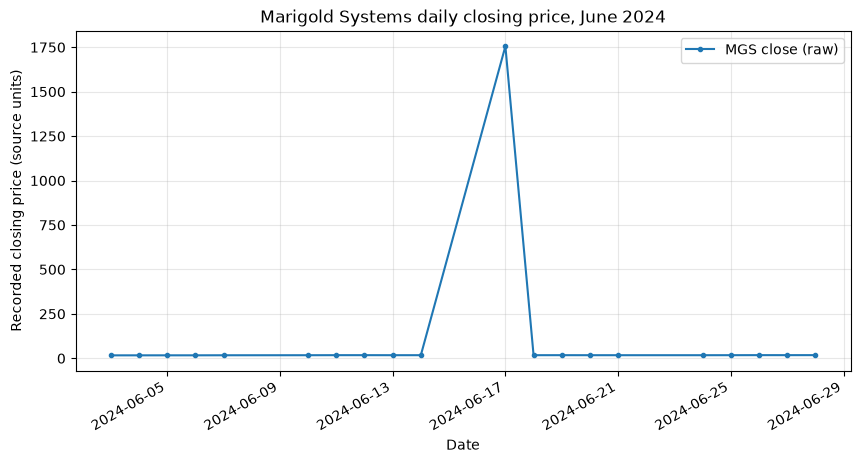

In [295]:
june_2024 = prices.loc[
    prices["Date"].between("2024-06-01", "2024-06-30")
].sort_values("Date")

fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(
    june_2024["Date"],
    june_2024["MGS"],
    marker="o",
    markersize=3,
    label="MGS close (raw)",
)
ax.set(
    title="Marigold Systems daily closing price, June 2024",
    xlabel="Date",
    ylabel="Recorded closing price (source units)",
)
ax.grid(alpha=0.3)
ax.legend()
fig.autofmt_xdate()
plt.show()


Compare the recorded and hypothesised values without changing `prices`. Percentage returns use the same chronological MGS observations on both sides of 17 June; the only scenario change is dividing that day's price by 100.


In [296]:
anomaly_date = pd.Timestamp("2024-06-17")
raw_mgs = prices.sort_values("Date").set_index("Date")["MGS"]
hypothesised_mgs = raw_mgs.copy()
hypothesised_mgs.loc[anomaly_date] /= 100

mgs_comparison = pd.DataFrame({
    "recorded_price": raw_mgs,
    "hypothesised_price": hypothesised_mgs,
    "recorded_return": raw_mgs.pct_change(),
    "hypothesised_return": hypothesised_mgs.pct_change(),
})
display(mgs_comparison.loc["2024-06-13":"2024-06-20"])
print("Recorded anomaly price:", f"{raw_mgs.loc[anomaly_date]:.6f}")
print("Hypothesised price:", f"{hypothesised_mgs.loc[anomaly_date]:.6f}")


,recorded_price,hypothesised_price,recorded_return,hypothesised_return
Date,,,,
2024-06-13,17.366235,17.366235,-0.010273,-0.010273
2024-06-14,17.383793,17.383793,0.001011,0.001011
2024-06-17,1755.506900,17.555069,99.985263,0.009853
2024-06-18,17.386902,17.386902,-0.990096,-0.009579
2024-06-19,17.476486,17.476486,0.005152,0.005152
2024-06-20,17.341453,17.341453,-0.007727,-0.007727


Recorded anomaly price: 1755.506900
Hypothesised price: 17.555069


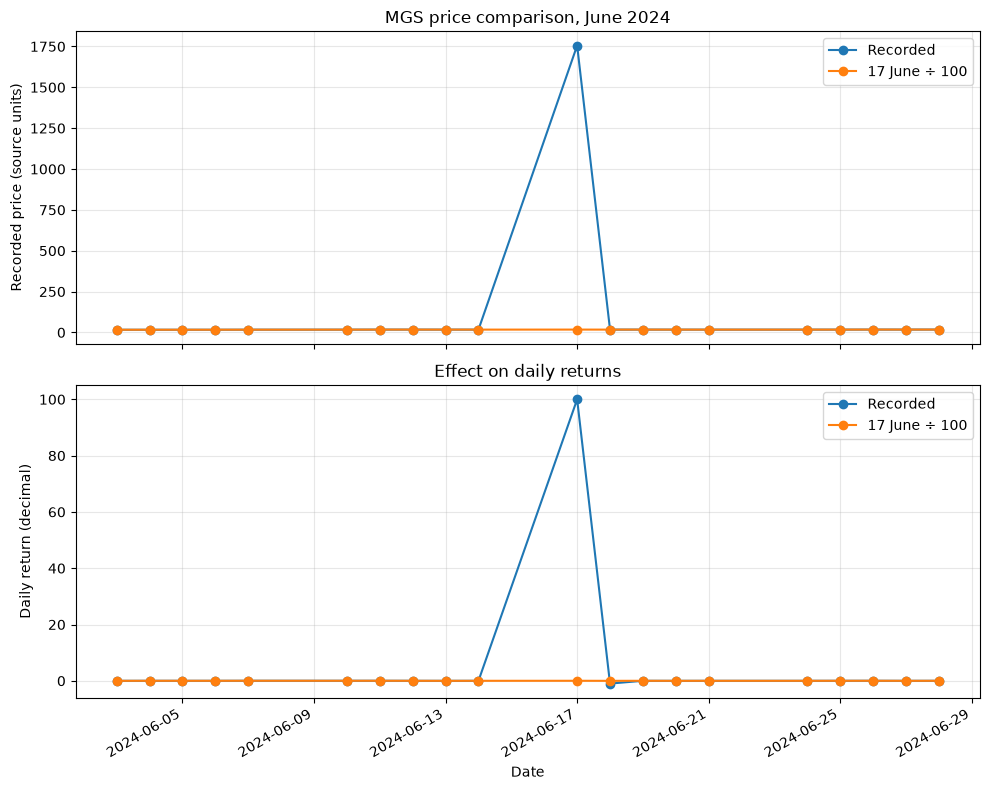

In [297]:
june_comparison = mgs_comparison.loc["2024-06-01":"2024-06-30"]
fig, axes = plt.subplots(2, 1, figsize=(10, 8), sharex=True)
axes[0].plot(june_comparison.index, june_comparison["recorded_price"], marker="o", label="Recorded")
axes[0].plot(june_comparison.index, june_comparison["hypothesised_price"], marker="o", label="17 June ÷ 100")
axes[0].set(title="MGS price comparison, June 2024", ylabel="Recorded price (source units)")
axes[1].plot(june_comparison.index, june_comparison["recorded_return"], marker="o", label="Recorded")
axes[1].plot(june_comparison.index, june_comparison["hypothesised_return"], marker="o", label="17 June ÷ 100")
axes[1].set(title="Effect on daily returns", xlabel="Date", ylabel="Daily return (decimal)")
for ax in axes:
    ax.grid(alpha=0.3)
    ax.legend()
fig.autofmt_xdate()
fig.tight_layout()
plt.show()


## ⭐ <u>10. Apply the Three Corrections</u>

Apply the project functions to copies of the raw data. The annual cleaner converts availability dates, rejects duplicate company-year identifiers, sorts records, corrects QCK 2025 free cash flow from 840.0 to −84.0 GBP million, and corrects the confirmed BSL 2025 profit transcription error from 1000.0 to 100.0 GBP million. The corrections apply only when the specified source values occur; sector-specific missing values remain missing. The daily cleaner converts and sorts dates, rejects duplicate dates and non-positive prices, then divides the 17 June 2024 MGS value by 100. `annual_clean` is a separate exploratory copy.

**Corrections applied:** **MGS 17 June 2024** price **1755.506900 → 17.555069**; **QCK 2025** FCF **£840m → −£84m**; **BSL 2025** profit **£1,000m → £100m**.


In [298]:
cleaned_annual_figures = clean_annual_figures(annual_figures)
cleaned_prices = clean_daily_prices(prices)

# Separate working copy for exploratory calculations such as expected FCF.
annual_clean = cleaned_annual_figures.copy()


## ⭐ <u>11. Verify the Corrections</u>

These checks report remaining missing values, invalid identifiers, dates, prices, and known source errors. The neighboring-year result is a review count, not a failed validation: legitimate changes can remain flagged after cleaning. The detailed cleaned-data flags appear below.

**Validation result:** The cleaned data has **zero FCF mismatches** and **zero remaining BSL 2025 profit errors**. The assertion cell below also checks the corrected **MGS 17 June 2024** price.


In [299]:
print("Daily price validation:")
display(pd.Series(validate_daily_prices(cleaned_prices), name="result").to_frame())
cleaned_annual_checks = validate_annual_figures(cleaned_annual_figures)
print("Cleaned annual validation:")
display(pd.Series(cleaned_annual_checks, name="result").to_frame())
cleaned_neighbor_flags = neighboring_year_outliers(cleaned_annual_figures)
print(f"Cleaned neighboring-year review flags: {len(cleaned_neighbor_flags)}")
display(cleaned_neighbor_flags)
print("Annual missing values:")
display(cleaned_annual_figures.isna().sum().rename("missing_count").to_frame())
print("Duplicate company-year identifiers:", cleaned_annual_figures.duplicated(["ticker", "year"]).sum())
print("Invalid annual availability dates:", cleaned_annual_figures["available_date"].isna().sum())
print("Non positive cleaned prices:", (cleaned_prices.drop(columns="Date") <= 0).sum().sum())


Daily price validation:


,result
duplicate_dates,0
invalid_dates,0
missing_prices,0
invalid_prices,0
dates_sorted,True
infinite_prices,0


Cleaned annual validation:


,result
duplicate_company_years,0
invalid_dates,0
missing_tickers,0
invalid_shares,0
fcf_mismatches,0


Cleaned neighboring-year review flags: 5


,ticker,date,metric,value,score,previous_value,next_value,reference_value,typical_change,reason
0,QCK,2025,profit_gbp_m,19.2,NaN,-4.05,NaN,-4.05,6.32,distance from adjacent year(s) >= 3 times loca...
1,QCK,2025,followers_thousands,5495.0,NaN,341.00,NaN,341.00,1138.00,distance from adjacent year(s) >= 3 times loca...
2,THL,2018,followers_thousands,4132.0,NaN,520.00,519.0,519.50,935.00,distance from adjacent year(s) >= 3 times loca...
3,THL,2025,followers_thousands,8981.0,NaN,2186.00,NaN,2186.00,935.00,distance from adjacent year(s) >= 3 times loca...
4,VTF,2025,followers_thousands,12460.0,NaN,2599.00,NaN,2599.00,1443.00,distance from adjacent year(s) >= 3 times loca...


Annual missing values:


,missing_count
ticker,0
company,0
sector,0
year,0
sales_gbp_m,0
profit_gbp_m,0
operating_cash_flow_gbp_m,30
capital_spending_gbp_m,30
free_cash_flow_gbp_m,30
debt_gbp_m,30


Duplicate company-year identifiers: 0
Invalid annual availability dates: 0
Non positive cleaned prices: 0


In [300]:
assert cleaned_annual_figures.shape == annual_figures.shape
assert cleaned_prices.shape == prices.shape
assert raw_annual_checks["fcf_mismatches"] == 1
assert cleaned_annual_checks["fcf_mismatches"] == 0
assert raw_annual_checks["bsl_2025_profit_errors"] == 1
assert cleaned_annual_checks["bsl_2025_profit_errors"] == 0
assert known_annual_errors(cleaned_annual_figures).empty
assert cleaned_annual_figures.loc[(cleaned_annual_figures["ticker"].eq("BSL")) & (cleaned_annual_figures["year"].eq(2025)), "profit_gbp_m"].iloc[0] == 100.0
cleaned_mgs_price = cleaned_prices.loc[
    cleaned_prices["Date"].eq(anomaly_date), "MGS"
].iloc[0]
assert abs(cleaned_mgs_price - raw_mgs.loc[anomaly_date] / 100) < 1e-10

print("Cleaned annual shape:", cleaned_annual_figures.shape)
print("Remaining FCF mismatches:", cleaned_annual_checks["fcf_mismatches"])
print("Cleaned daily shape:", cleaned_prices.shape)
print("Cleaned MGS price on 17 June 2024:", f"{cleaned_mgs_price:.6f}")


KeyError: 'bsl_2025_profit_errors'

## 12. Save the Cleaned Data

After the checks above pass, save both cleaned tables as CSV files in `data/cleaned`. Empty sector-specific fields remain empty. Rerunning this cell replaces the previous cleaned CSV files with the current cleaned DataFrames. The dates are written in `YYYY-MM-DD` form.


In [ ]:
from src.data_loader import save_cleaned_data

annual_path, prices_path = save_cleaned_data(
    cleaned_annual_figures, cleaned_prices, project_root / "data" / "cleaned"
)
print("Saved cleaned annual figures:", annual_path)
print("Saved cleaned daily prices:", prices_path)


## ⭐ <u>13. Key Findings for Presentation</u>

- A visual scan of **annual sales for all 20 companies** and **raw daily prices for all 20 companies** exposed an isolated MGS spike in mid 2024, which led to the focused June investigation.
- The source contains **200 annual observations** and **2,529 daily observations**. No duplicate records, invalid dates, or non positive daily prices were found in this workbook.
- Annual sector specific fields contain missing values; the annual cleaner preserves them. Of 170 comparable FCF rows, **QCK 2025 — FCF discrepancy:** reported 840.0 GBP million versus −84.0 from operating cash flow minus capital spending. The targeted correction leaves zero FCF mismatches; 30 rows lack the inputs for this comparison. No missing values were found in the daily price sheet.
- The neighboring-year screen checks every numeric annual measure. It flags 7 raw observations and 5 cleaned observations for review; **BSL 2025 — profit transcription error:** £1,000m was corrected to £100m and is no longer flagged. Remaining flags are not automatically classified as errors.
- **MGS 17 June 2024 — price spike:** The recorded price is **1755.506900**. The existing cleaner applies the **÷ 100** correction, producing **17.555069**; a GBX to GBP unit mismatch remains an unverified hypothesis.
- The correction changes the MGS daily returns on 17 and 18 June 2024 from approximately **+9,998.5%** and **−99.01%** to **+0.985%** and **−0.958%** respectively.
- Cleaning converts date fields, sorts records, checks duplicate identifiers and non positive prices, and applies the documented MGS, QCK FCF, and BSL 2025 profit corrections. BSL profit changes from 1000.0 to 100.0 GBP million. Section 12 saves the cleaned DataFrames under `data/cleaned`.
- Before modelling or backtesting, confirm the MGS source unit with the data provider and decide how to handle sector specific missing fields for each analysis.
